# Load in the downloaded ERA5 data and interpolate it onto a coarser grid

Author: Brian Green (briangre@stanford.edu)

In [1]:
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import netCDF4 as nc
import cartopy.crs as ccrs
import matplotlib.ticker as mticker
import xarray as xr
from scipy import interpolate

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    tqdm.pandas()

%matplotlib inline

### Constants

In [2]:
g = 9.806 # (m/s**2); acceleration due to gravity
cp = 1005 # (J/kg/K); the specific heat at constant pressure
R = 287 # (J/kg/K); the gas constant for dry air
p0 = 1000 # (hPa); the reference pressure for the potential temperature calculation
r = 6.371E6 # (m) the mean radius of the Earth

### Load in the data

In [3]:
# Define the dataset
file_path = str('../temperature/Jan2011.nc')
dataset = nc.Dataset(file_path)
print(dataset.variables)

# Load in the variables from the first file
time = np.array(dataset.variables['valid_time']).astype('timedelta64[s]')
time = np.datetime64('1970-01-01') + time
lat = np.array(dataset.variables['latitude']) # (deg. N)
lon = np.array(dataset.variables['longitude']) # (deg. E)
pressure = np.array(dataset.variables['pressure_level']) # (hPa)
temperature = np.array(dataset.variables['t']) # (K)
[n_time,n_pressure,n_lat,n_lon] = temperature.shape

# Copy longitude = -180 data to longitude = +180,
# to help with the interpolation near the date line
temp = np.nan*np.ones(shape=(n_time,n_pressure,n_lat,1))
temp[:,:,:,0] = temperature[:,:,:,0]
temperature = np.append(temperature,temp,axis=3)
del temp

{'number': <class 'netCDF4._netCDF4.Variable'>
int64 number()
    long_name: ensemble member numerical id
    units: 1
    standard_name: realization
unlimited dimensions: 
current shape = ()
filling on, default _FillValue of -9223372036854775806 used, 'valid_time': <class 'netCDF4._netCDF4.Variable'>
int64 valid_time(valid_time)
    long_name: time
    standard_name: time
    units: seconds since 1970-01-01
    calendar: proleptic_gregorian
unlimited dimensions: 
current shape = (744,)
filling on, default _FillValue of -9223372036854775806 used, 'pressure_level': <class 'netCDF4._netCDF4.Variable'>
float64 pressure_level(pressure_level)
    _FillValue: nan
    long_name: pressure
    units: hPa
    positive: down
    stored_direction: decreasing
    standard_name: air_pressure
unlimited dimensions: 
current shape = (7,)
filling on, 'latitude': <class 'netCDF4._netCDF4.Variable'>
float64 latitude(latitude)
    _FillValue: nan
    units: degrees_north
    standard_name: latitude
    lon

### Calculate the buoyancy frequency

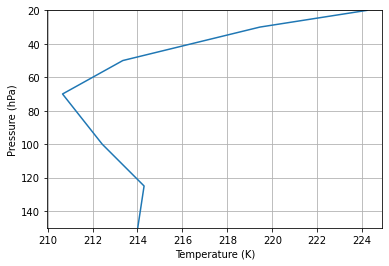

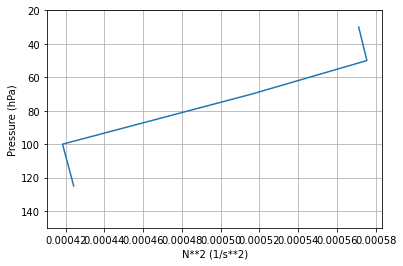

In [4]:
# I'm assuming the atmosphere is in hydrostatic balance, so
# N**2 = (g/theta)*(dtheta/dz)
#      = (g/theta)*(dtheta/dp)*(dp/dz)
#      = -(rho*g**2/theta)*(dtheta/dp)
pressure_tiled = np.tile(pressure,(n_lon+1,n_lat,1)).swapaxes(0,2)
pressure_cellfaces = 0.5*(pressure[1:] + pressure[:-1])
dp = 100*(pressure[1:] - pressure[:-1]) # convert pressure to units of Pa
dp = np.tile(dp,(n_lon+1,n_lat,1)).swapaxes(0,2)

# The size of the reanalysis fields means that I must do this for each time step,
# to save memory
N2 = np.nan*np.ones(shape=(n_time,n_pressure,n_lat,n_lon+1))
for i in np.arange(n_time):
    
    # Calculate the potential temperature
    theta = temperature[i,:,:,:]*(p0/pressure_tiled)**(R/cp)

    # Take the vertical derivative w/r/t pressure
    dtheta = theta[1:,:,:] - theta[:-1,:,:]
    dthetadp = dtheta/dp

    # Linearly interpolate back to the cell centers
    f = interpolate.interp1d(pressure_cellfaces, dthetadp, axis=0)
    dthetadp = f(pressure[1:-1])

    # Calculate the buoyancy frequency at the cell faces
    rho = 100*pressure_tiled/(R*temperature[i,:,:,:]) # convert pressure to units of Pa
    N2[i,1:-1,:,:] = -(rho[1:-1,:,:]/theta[1:-1,:,:])*(g**2)*dthetadp
    
# Make a couple plots, as a sanity check
ind1 = 1
ind2 = 10
ind3 = 1000

plt.figure()
plt.plot(temperature[ind1,:,ind2,ind3], pressure)
plt.grid()
plt.ylim(np.max(pressure),np.min(pressure))
plt.xlabel('Temperature (K)')
plt.ylabel('Pressure (hPa)');

plt.figure()
plt.plot(N2[ind1,:,ind2,ind3], pressure)
plt.grid()
plt.ylim(np.max(pressure),np.min(pressure))
plt.xlabel('N**2 (1/s**2)')
plt.ylabel('Pressure (hPa)');

### Interpolate onto a coarser grid

In [5]:
# The native ERA5 grid
dlat = lat[0] - lat[1]
dlon = lon[1] - lon[0]

# Calculate the areas of the native ERA5 grid cells, accounting for the South Pole
lat_faces = (lat[0] - dlat/2)*np.ones(n_lat+1)
lat_faces[1:-1] = 0.5*(lat[1:] + lat[:-1])
lat_faces[-1] = -90
cell_areas = (dlon*np.pi/180)*(r**2)*(np.sin(lat_faces[:-1]*np.pi/180) - 
                                      np.sin(lat_faces[1:]*np.pi/180))
cell_areas = np.tile(cell_areas,(n_lon+1,1)).swapaxes(0,1)

# Define the coarse grid
# The resolution must be an integer multiple of the native ERA5 grid
# The grid cells must be centered on grid cells in the native ERA5 grid
dlat_coarse = 5 # (deg)
dlon_coarse = 10 # (deg)
lat_start_coarse = -37.5 # (deg N)
lon_start_coarse = -175 # (deg E)
n_lat_coarse = 11 # 5deg, 35S to 90S
n_lon_coarse = 36 # 10deg, 180W to 180E 
lat_coarse = lat_start_coarse - dlat_coarse*np.arange(n_lat_coarse)
lon_coarse = lon_start_coarse + dlon_coarse*np.arange(n_lon_coarse)

# Define the stencil for area averaging
n_lat_stencil = 1 + int(dlat_coarse/dlat)
n_lon_stencil = 1 + int(dlon_coarse/dlon)
stencil = np.ones(shape=(n_lat_stencil,n_lon_stencil))
# The edges only include half of the native ERA5 grid cells; the corners only a quarter
stencil[0,:] = 0.5*stencil[0,:]
stencil[-1,:] = 0.5*stencil[-1,:]
stencil[:,0] = 0.5*stencil[:,0]
stencil[:,-1] = 0.5*stencil[:,-1]
# Tile the cell areas and stencil to have the right dimensions
stencil = np.tile(stencil,(n_time,n_pressure,1,1))

# Do the interpolation
temperature_coarse = np.nan*np.ones(shape=(n_time,n_pressure,n_lat_coarse,n_lon_coarse))
N2_coarse = np.nan*np.ones(shape=(n_time,n_pressure,n_lat_coarse,n_lon_coarse))

for i in np.arange(n_lat_coarse):
    
    print(i+1, n_lat_coarse)
    lat_ind1 = i*int(dlat_coarse/dlat)
    lat_ind2 = i*int(dlat_coarse/dlat) + n_lat_stencil
    
    for j in np.arange(n_lon_coarse):
        
        # Define the stencil
        lon_ind1 = j*int(dlon_coarse/dlon)
        lon_ind2 = j*int(dlon_coarse/dlon) + n_lon_stencil
        cell_areas_temp = np.tile(cell_areas[lat_ind1:lat_ind2,lon_ind1:lon_ind2],(n_time, n_pressure, 1, 1))
        
        # Temperature
        var_temp = temperature[:,:,lat_ind1:lat_ind2,lon_ind1:lon_ind2]
        # The areas of each grid cell in the stencil, accounting for any NaNs in the data
        factor = var_temp.copy()
        factor[factor == 0] = 1
        factor = factor/factor
        factor = factor*cell_areas_temp*stencil
        # The area-weighted sum over the stencil
        temperature_coarse[:,:,i,j] = np.nansum(factor*var_temp,axis=(2,3))/np.nansum(factor,axis=(2,3))
        
        # N**2
        var_temp = N2[:,:,lat_ind1:lat_ind2,lon_ind1:lon_ind2]
        # The areas of each grid cell in the stencil, accounting for any NaNs in the data
        factor = var_temp.copy()
        factor[factor == 0] = 1
        factor = factor/factor
        factor = factor*cell_areas_temp*stencil
        # The area-weighted sum over the stencil
        N2_coarse[:,:,i,j] = np.nansum(factor*var_temp,axis=(2,3))/np.nansum(factor,axis=(2,3))

1 11


/var/folders/dw/3jtpv5j16bv77dfbt2nw04780000gp/T/ipykernel_9683/3927483006.py:72: RuntimeWarning: invalid value encountered in true_divide
  N2_coarse[:,:,i,j] = np.nansum(factor*var_temp,axis=(2,3))/np.nansum(factor,axis=(2,3))


2 11
3 11
4 11
5 11
6 11
7 11
8 11
9 11
10 11
11 11


### Plot a time slice to check the interpolation worked

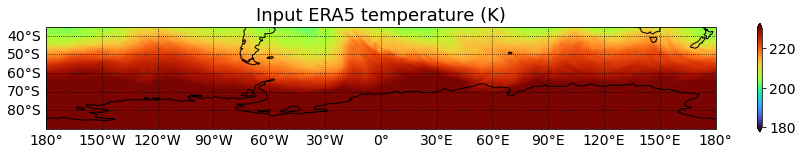

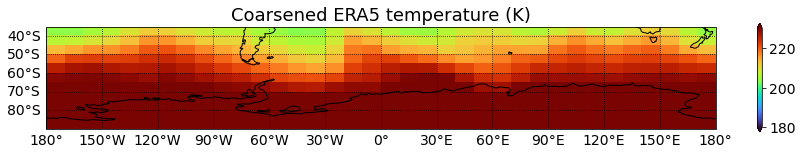

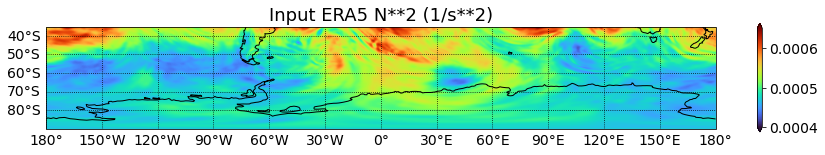

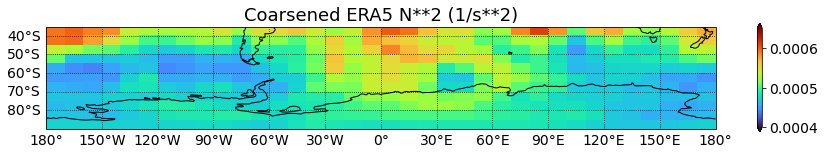

In [6]:
time_ind_to_plot = 100
pressure_ind_to_plot = 3

plt.figure(figsize=(15,2))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=0.0, globe=None))
ax.set_extent([-180, 180, -90, -35], crs=ccrs.PlateCarree())
ax.coastlines(resolution='110m') # Options are 110m, 50m, 10m
gl = ax.gridlines(draw_labels=True, color='k', linestyle=':')
gl.top_labels = False
gl.right_labels = False
gl.xlocator = mticker.FixedLocator(np.arange(-180.,181.,30))
gl.ylocator = mticker.FixedLocator(np.arange(-90.,91.,10))
data = temperature[time_ind_to_plot,pressure_ind_to_plot,:,:].copy()
plt.imshow(data, cmap = 'turbo', extent=(-180,180,-90,-35), transform=ccrs.PlateCarree())
gl.xlabel_style = {'size': 14}
gl.ylabel_style = {'size': 14}
plt.title('Input ERA5 temperature (K)', fontsize=18)
plt.clim(180,230)
cbar = plt.colorbar(extend='both')
cbar.ax.tick_params(labelsize=14);
#plt.savefig('temp1.png', format='png', bbox_inches='tight');

plt.figure(figsize=(15,2))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=0.0, globe=None))
ax.set_extent([-180, 180, -90, -35], crs=ccrs.PlateCarree())
ax.coastlines(resolution='110m') # Options are 110m, 50m, 10m
gl = ax.gridlines(draw_labels=True, color='k', linestyle=':')
gl.top_labels = False
gl.right_labels = False
gl.xlocator = mticker.FixedLocator(np.arange(-180.,181.,30))
gl.ylocator = mticker.FixedLocator(np.arange(-90.,91.,10))
data = temperature_coarse[time_ind_to_plot,pressure_ind_to_plot,:,:].copy()
plt.imshow(data, cmap = 'turbo', extent=(-180,180,-90,-35), transform=ccrs.PlateCarree())
gl.xlabel_style = {'size': 14}
gl.ylabel_style = {'size': 14}
plt.title('Coarsened ERA5 temperature (K)', fontsize=18)
plt.clim(180,230)
cbar = plt.colorbar(extend='both')
cbar.ax.tick_params(labelsize=14);
#plt.savefig('temp1.png', format='png', bbox_inches='tight');



plt.figure(figsize=(15,2))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=0.0, globe=None))
ax.set_extent([-180, 180, -90, -35], crs=ccrs.PlateCarree())
ax.coastlines(resolution='110m') # Options are 110m, 50m, 10m
gl = ax.gridlines(draw_labels=True, color='k', linestyle=':')
gl.top_labels = False
gl.right_labels = False
gl.xlocator = mticker.FixedLocator(np.arange(-180.,181.,30))
gl.ylocator = mticker.FixedLocator(np.arange(-90.,91.,10))
data = N2[time_ind_to_plot,pressure_ind_to_plot,:,:].copy()
plt.imshow(data, cmap = 'turbo', extent=(-180,180,-90,-35), transform=ccrs.PlateCarree())
gl.xlabel_style = {'size': 14}
gl.ylabel_style = {'size': 14}
plt.title('Input ERA5 N**2 (1/s**2)', fontsize=18)
plt.clim(0.0004,0.00065)
cbar = plt.colorbar(extend='both')
cbar.ax.tick_params(labelsize=14);
#plt.savefig('temp1.png', format='png', bbox_inches='tight');

plt.figure(figsize=(15,2))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=0.0, globe=None))
ax.set_extent([-180, 180, -90, -35], crs=ccrs.PlateCarree())
ax.coastlines(resolution='110m') # Options are 110m, 50m, 10m
gl = ax.gridlines(draw_labels=True, color='k', linestyle=':')
gl.top_labels = False
gl.right_labels = False
gl.xlocator = mticker.FixedLocator(np.arange(-180.,181.,30))
gl.ylocator = mticker.FixedLocator(np.arange(-90.,91.,10))
data = N2_coarse[time_ind_to_plot,pressure_ind_to_plot,:,:].copy()
plt.imshow(data, cmap = 'turbo', extent=(-180,180,-90,-35), transform=ccrs.PlateCarree())
gl.xlabel_style = {'size': 14}
gl.ylabel_style = {'size': 14}
plt.title('Coarsened ERA5 N**2 (1/s**2)', fontsize=18)
plt.clim(0.0004,0.00065)
cbar = plt.colorbar(extend='both')
cbar.ax.tick_params(labelsize=14);
#plt.savefig('temp1.png', format='png', bbox_inches='tight');

### Save the data

In [7]:
df = xr.DataArray(temperature_coarse, coords=[('time',time), ('pressure',pressure),
                                      ('latitude',lat_coarse), ('longitude',lon_coarse)])
df.to_netcdf('temp_data/Jan2011_temperature_coarse.nc')
print(df)
print()
print()

df = xr.DataArray(N2_coarse, coords=[('time',time), ('pressure',pressure),
                                     ('latitude',lat_coarse), ('longitude',lon_coarse)])
df.to_netcdf('temp_data/Jan2011_N2_coarse.nc')
print(df)

<xarray.DataArray (time: 744, pressure: 7, latitude: 11, longitude: 36)>
array([[[[214.30231021, 211.29137869, 213.45613606, ..., 210.23964606,
          211.16694524, 217.22895422],
         [219.68302692, 213.12257883, 213.26829984, ..., 211.34741329,
          212.27598986, 220.46885552],
         [222.8567211 , 217.58542044, 215.21279203, ..., 217.8045939 ,
          216.3670264 , 221.96854633],
         ...,
         [226.20164464, 225.10820443, 224.01322061, ..., 227.14581488,
          227.38623965, 227.08071422],
         [224.55030785, 223.72492825, 223.10407281, ..., 226.1131171 ,
          225.84417134, 225.37122592],
         [224.50400261, 224.34605458, 224.16628851, ..., 224.75051222,
          224.70032529, 224.60825825]],

        [[209.97935765, 209.10783201, 209.39581978, ..., 207.30704311,
          209.93897689, 212.42117725],
         [215.90838629, 212.69099461, 212.81644446, ..., 210.58269914,
          212.94206821, 217.6172487 ],
         [219.90910454, 216.816